# Gaming and Mental Health - Causal Inference Project

**By Faatimah Majothi**

## Introduction

Digital gaming has existed as far back as the 1970's and has seen a steep incline in the last decade coinciding with technological development. Concerns surrounding the impacts of digital gaming on health, both mental and physical, have existed for just as long, with a growing focus on the mental impacts in recent years. As digital gaming becomes more accessible and therefore widespread, the question of whether it directly causes or amplifies mental health issues is more crucial than ever.


In this project we will use the principles of a Causal Inference workflow to investigate the relationship between digital gaming and mental health. We aim to complete a clean data analysis project that showcases an understanding of causal inference analysis along with proficiency in the use of python libraries and machine learning models. 


As a reminder, a key point in any analysis of a relationship between two variables is that **correlation does not always indicate causation**.

**Project Scope:**

**Jupyter Notebook (Current):**

- A: Define the problem and variables
  - Create a detailed DAG (Directed Acyclic Graph) using knowledge and assumptions about the data generating process (DGP).
  - Identify the treatment, outcome, and confounders from the DAG.
- B: Import, explore, and preprocess the data
  - Import the dataset and perform exploratory data analysis (EDA).
  - Check the available data against the assumptions of causal inference.
  - Preprocess the data as needed.

**R Notebook (Following):**

- C: Estimate propensity scores and adjust for confounding
  - Estimate propensity scores by fitting a model to predict treatment assignment using confounders.
  - Apply a causal inference method.
  - Assess balance between treatment and control groups after adjustment.
- D: Estimate and validate the causal effect
  - Fit an outcome model to estimate the causal effect (ATE) using the adjusted data.
  - Calculate robust standard errors to account for weighting or matching.
  - Validate model results and check for robustness using refuters or sensitivity analysis.
- Conclusion: Interpret and communicate the estimated causal effect of gaming hours on overall mental health.


> The continuation of the project is available in the .Rmd file existing in the parent GitHub repository.

> Link: [caus_inf_spec2.Rmd]('https://github.com/FaatimahMajothi98/Causal-Inference-Analysis/blob/master/caus_inf_spec2.Rmd')

### **Section A:** Causal DAG and Assumptions

In [29]:
# Setup
import os
from PIL import Image

# Import Libraries
import pandas as pd
import numpy as np

# Inference
import dowhy
from dowhy import CausalModel

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report,\
confusion_matrix, classification_report, ConfusionMatrixDisplay

# Set visualisation theme
from matplotlib import pyplot as plt
import seaborn as sns
plt.rcParams['figure.facecolor'] = '#F7F0DE'
plt.rcParams['axes.facecolor'] = '#FFFFFF'

# Data
import gdown
import zipfile

# Download zip file
url = 'https://drive.google.com/uc?export=download&id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi'
gdown.download(url, 'data.zip', quiet=False)

# Extract zip file
with zipfile.ZipFile('data.zip', 'r') as zip_ref:
    zip_ref.extractall('data_folder')

inf_data = pd.read_csv('data_folder/gaming_mental_health_10M_40features.csv')
inf_data.head(3)


Downloading...
From (original): https://drive.google.com/uc?id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi
From (redirected): https://drive.google.com/uc?id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi&confirm=t&uuid=f8396385-d402-4855-bbb5-da2f55f44414
To: d:\Data Science F\Projects\causal_inference\data.zip
100%|██████████| 67.4M/67.4M [00:02<00:00, 25.0MB/s]


,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
0,51,Female,8615,3.68,22,17,5.26,1.00,0.18,3,...,0,2.87,3.19,5.20,19.69,4.71,5.71,4.81,80,10
1,41,Female,39453,5.70,34,16,9.20,0.70,1.44,8,...,7,4.17,7.73,5.40,26.37,6.62,6.77,3.99,57,2
2,27,Male,40466,1.58,8,22,7.39,2.24,3.15,3,...,9,9.38,2.85,5.17,25.15,9.30,2.16,4.75,59,10


**Identify variables:**


- X: Digital gaming habits
- Y: Mental health (stress/depression/etc.)
- Z: Confounders:
    - Income
    - Sleep
    - Caffiene/Drugs/Alcohol
    - Age
    - Activity
    - Health
    - Social activity
    - Work/Study

###### **There are many other possible confounders/variables that impact gaming habits and mental health, but these are some key points of interest.**

In [30]:
# Digraph syntax
causal_graph = """
digraph{
    age -> income;
    study_work -> gaming_hrs;
    study_work -> income;
    sleep -> m_health;
    m_health -> sleep_hrs;
    m_health -> socialising;
    study_work -> socialising;
    online_friends -> gaming_hrs;
    age -> restrictions;
    restrictions -> gaming_hrs;
    activity -> p_health;
    study_work -> activity;
    socialising -> gaming_hrs;
    p_health -> m_health;
    gaming_hrs -> m_health;
}
"""

# Variables DataFrame syntax
variables_df = pd.DataFrame(['age', 'income', 'study_work', 'gaming_hrs', 'sleep', 'm_health', 'sleep_hrs', 'socialising', 'online_friends', 'restrictions', 'activity', 'p_health']
)

The confounding variables we identified in the digraph code are present in the data available. Some of the columns in the data, such as `stress_level` and `depression_score` both fall under our `m_health` (overall mental health) variable. More confounding variables are likely present, but we have selected limited variables for `variables_df` to remain within the constraints of data usage for this project. This can be considered a **limitation** of the project. 

In [31]:
# DAG visualisation

dag_model = CausalModel(
    data=variables_df,
    graph=causal_graph,
    treatment='gaming',
    outcome='m_health'
)
dag_model.view_model()

If the above cell does not render the DAG diagram, the diagram below can be referenced instead:

![DAG diagram](mhealth_gaming_dag.jpeg)

In [32]:
# Identify the treatment, outcome, and confounders
print(inf_data.columns)

treat_var = 'm_health'
outcome = 'gaming_hrs'

Index(['age', 'gender', 'income', 'daily_gaming_hours', 'weekly_sessions',
       'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
       'stress_level', 'anxiety_score', 'depression_score',
       'social_interaction_score', 'relationship_satisfaction',
       'academic_performance', 'work_productivity', 'addiction_level',
       'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
       'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
       'friends_gaming_count', 'online_friends', 'streaming_hours',
       'esports_interest', 'headset_usage', 'microtransactions_spending',
       'parental_supervision', 'loneliness_score', 'aggression_score',
       'happiness_score', 'bmi', 'screen_time_total', 'eye_strain_score',
       'back_pain_score', 'competitive_rank', 'internet_quality'],
      dtype='str')


From the columns in the inf_data DataFrame, the **treatment** variable `m_health` and the **outcome** variable `gaming_hrs` are not represented by single columns. Instead, several columns hold information about each row’s mental health and time spent gaming.

### **Section B:** EDA and Preprocessing

We now have the DAG as a starting point to our analysis of causality. However, the preview of available columns in the dataset highlighted that we do not yet have a clear treatment or outcome variable. To address this, we will begin familiarising with the contents of the dataset before deciding how to assign our existing data to our `gaming_hrs` **treatment** and `m_health` **outcome** variables.

##### **EDA:**

Before we can begin any kind of data wrangling, it is good practice to explore the raw dataset.
First, we will use visualisations and summary statistics to explore the available columns in the `inf_data` DataFrame for our EDA (Exploratory Data Analysis). Then, we will try to identify any issues and determine what changes need to be made in the preprocessing step.

**Note: The dataset used in this project was sourced from [Kaggle](https://www.kaggle.com/datasets/sharmajicoder/gaming-and-mental-health) and contains synthetic data - this is a limitation of the project.**

In [33]:
# Preview data to be cleaned
print('DataFrame summary:')
inf_data.info()
print('\n')

for col in inf_data.columns:
    print('________________________________________________________________________________')
    print(f'{col} column information:\n')
    print(f'{col} data type: {inf_data[col].dtype}\n')
    print(f'{col} description: {inf_data[col].describe()}\n')
    if inf_data[col].nunique() <= 12:
        print(f'{col} values: {inf_data[col].unique()}\n')
    else:
        print(f'{col} value range: {inf_data[col].min()} to {inf_data[col].max()}\n')


DataFrame summary:
<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  str    
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  social_interaction_score    1000000 non-null  flo

From the summary statistics of the `inf_data` dataframe, we can see that there are **no null values**. The ranges of the numeric data do not appear to have unrealistic outliers or impossible values (such as negative scores).

However, the dataset contains 1,000,000 rows. While this is advantageous for causal inference, the size of the data presents **computational and memory challenges** for an introductory project such as this one. To address this, we will **randomly sample** a smaller subset of the data with the goal of reducing the computational demands while maintaining a representative, balanced distribution of the variables. 
In doing so, we aim to end up with a dataset that more closely resembles real-world data.

For this project, we will be using **simple random sampling** to subset 15% of the data, which is slightly above the 10% standard. This should replicate a balanced representation of the whole dataset, as each point has an equal chance of being selected.

In [34]:
# Simple random sampling
seed = 24
df = inf_data.sample(frac=0.15, random_state=seed)
print(df.columns)
df.info()

Index(['age', 'gender', 'income', 'daily_gaming_hours', 'weekly_sessions',
       'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
       'stress_level', 'anxiety_score', 'depression_score',
       'social_interaction_score', 'relationship_satisfaction',
       'academic_performance', 'work_productivity', 'addiction_level',
       'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
       'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
       'friends_gaming_count', 'online_friends', 'streaming_hours',
       'esports_interest', 'headset_usage', 'microtransactions_spending',
       'parental_supervision', 'loneliness_score', 'aggression_score',
       'happiness_score', 'bmi', 'screen_time_total', 'eye_strain_score',
       'back_pain_score', 'competitive_rank', 'internet_quality'],
      dtype='str')
<class 'pandas.DataFrame'>
Index: 150000 entries, 266400 to 718991
Data columns (total 39 columns):
 #   Column                      Non-

The reduced dataframe of 150,000 entries will now be less computationally taxing. Now, we will check the distributions of both the full and reduced dataframes in order to determine whether our sampled dataframe is balanced and representitive of the original data.

./png_full\agedist.png already exists; importing...


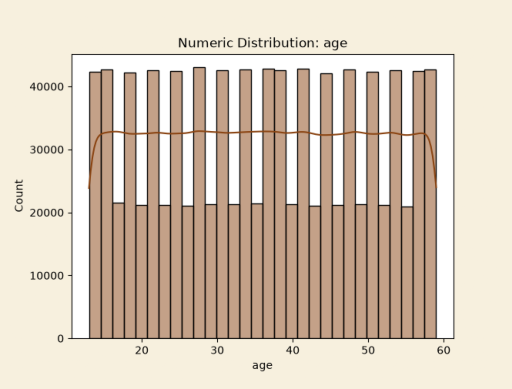

./png_full\genderdist.png already exists; importing...


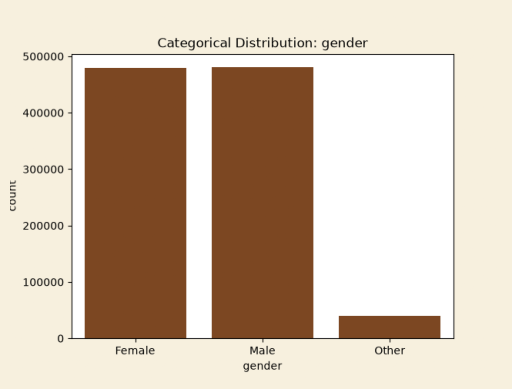

./png_full\incomedist.png already exists; importing...


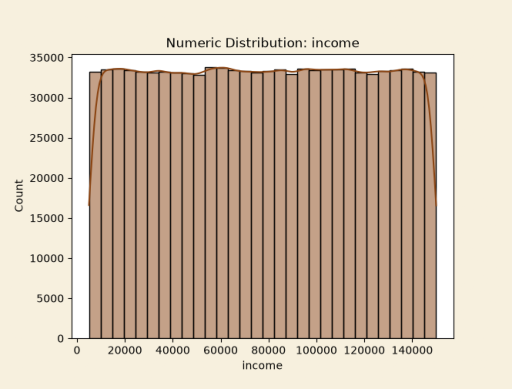

./png_full\daily_gaming_hoursdist.png already exists; importing...


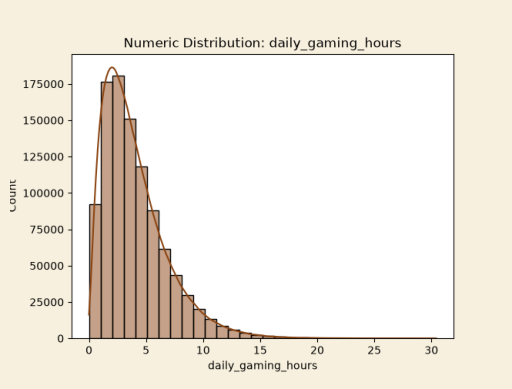

./png_full\weekly_sessionsdist.png already exists; importing...


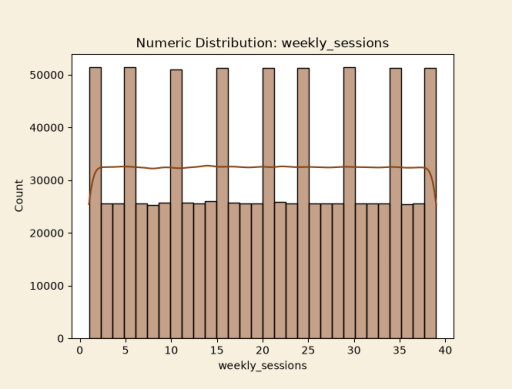

./png_full\years_gamingdist.png already exists; importing...


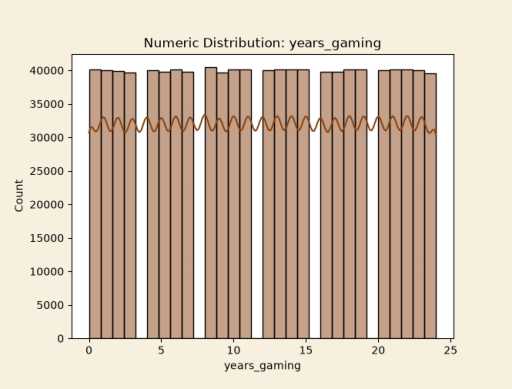

./png_full\sleep_hoursdist.png already exists; importing...


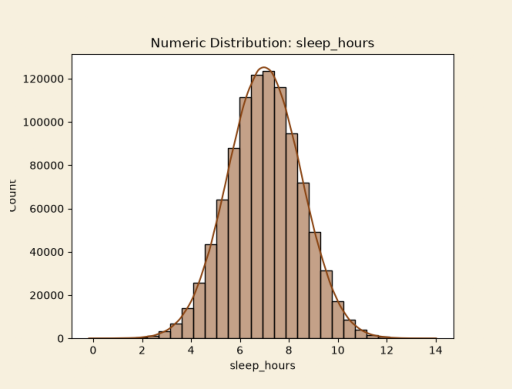

./png_full\caffeine_intakedist.png already exists; importing...


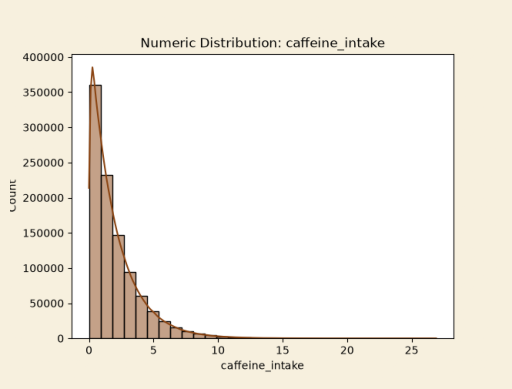

./png_full\exercise_hoursdist.png already exists; importing...


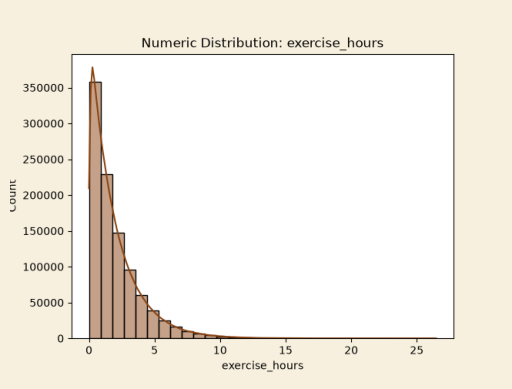

./png_full\stress_leveldist.png already exists; importing...


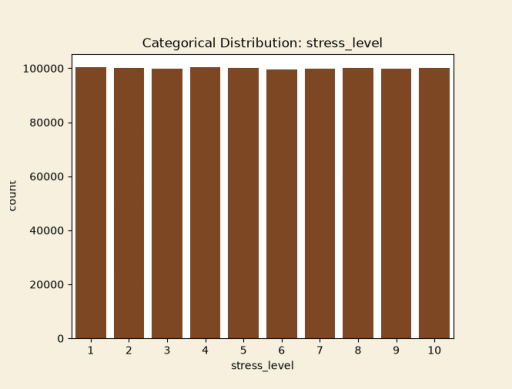

./png_full\anxiety_scoredist.png already exists; importing...


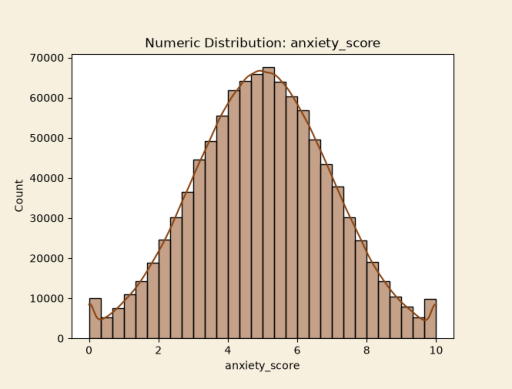

./png_full\depression_scoredist.png already exists; importing...


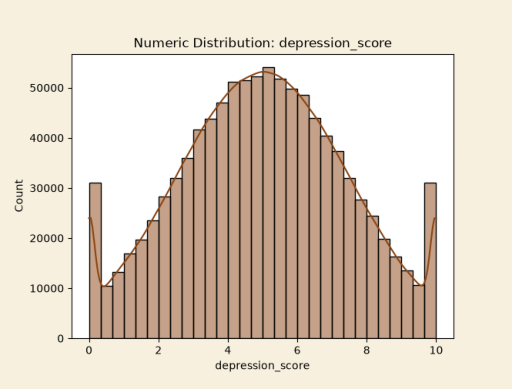

./png_full\social_interaction_scoredist.png already exists; importing...


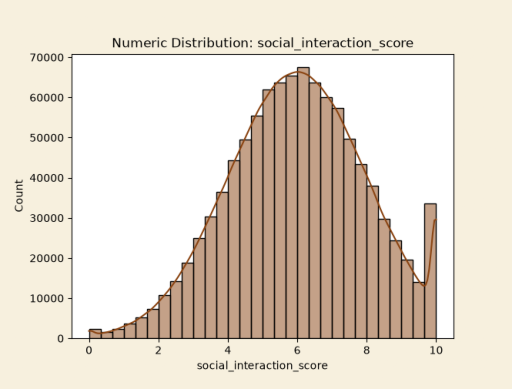

./png_full\relationship_satisfactiondist.png already exists; importing...


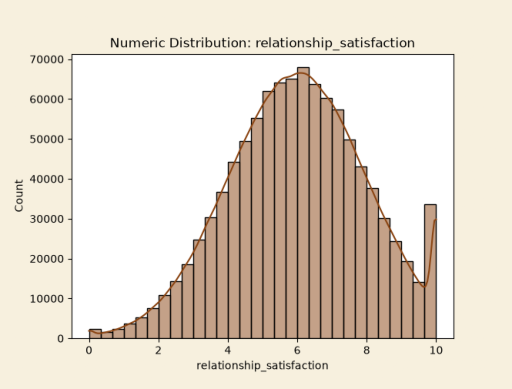

./png_full\academic_performancedist.png already exists; importing...


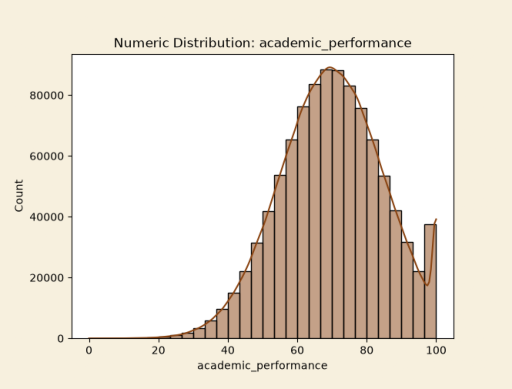

./png_full\work_productivitydist.png already exists; importing...


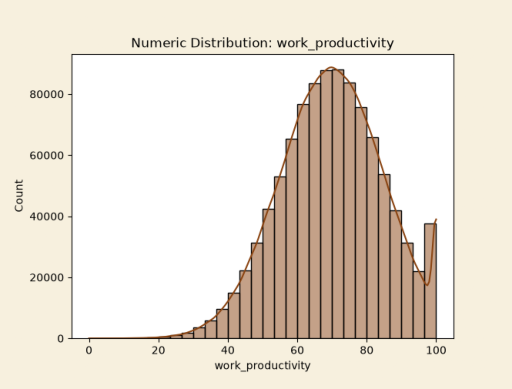

./png_full\addiction_leveldist.png already exists; importing...


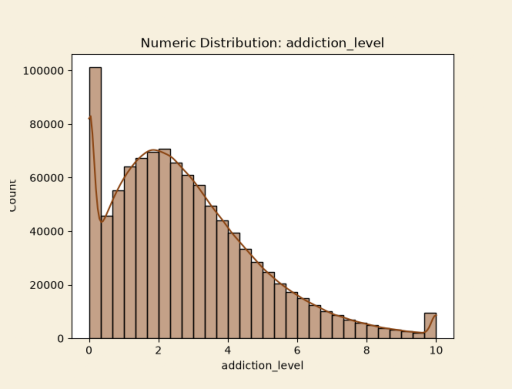

./png_full\multiplayer_ratiodist.png already exists; importing...


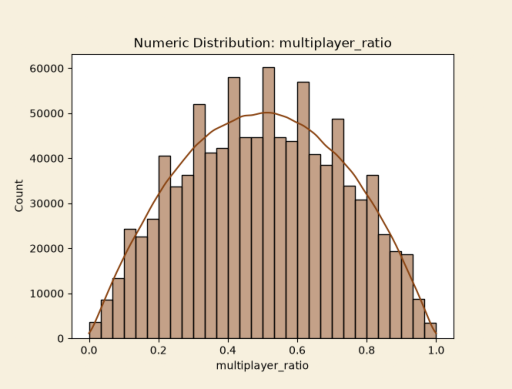

./png_full\toxic_exposuredist.png already exists; importing...


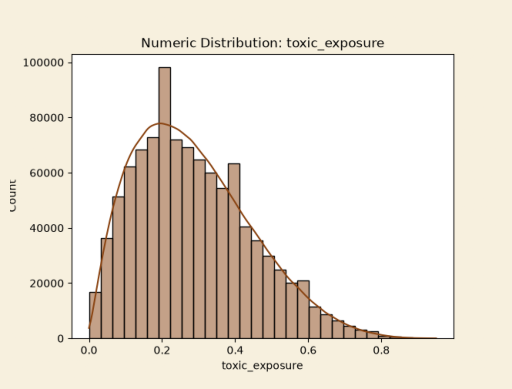

./png_full\violent_games_ratiodist.png already exists; importing...


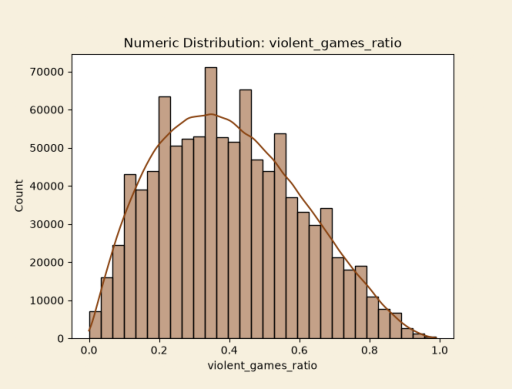

./png_full\mobile_gaming_ratiodist.png already exists; importing...


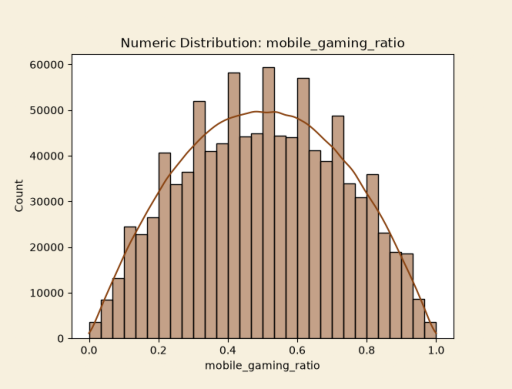

./png_full\night_gaming_ratiodist.png already exists; importing...


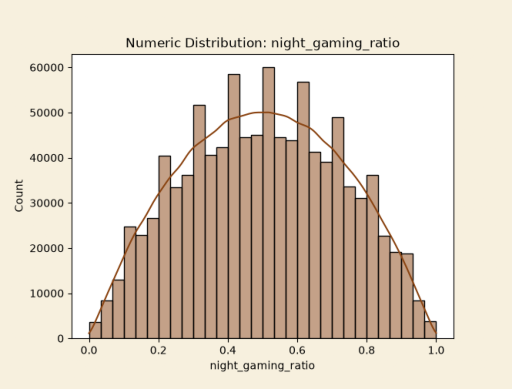

./png_full\weekend_gaming_hoursdist.png already exists; importing...


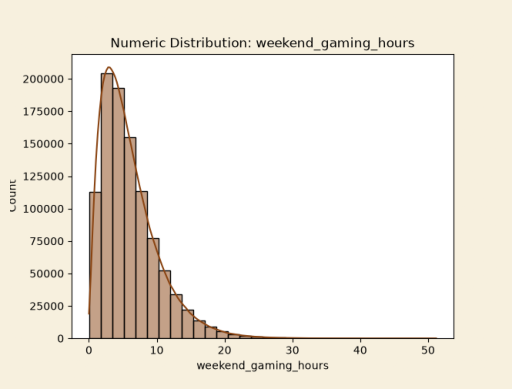

./png_full\friends_gaming_countdist.png already exists; importing...


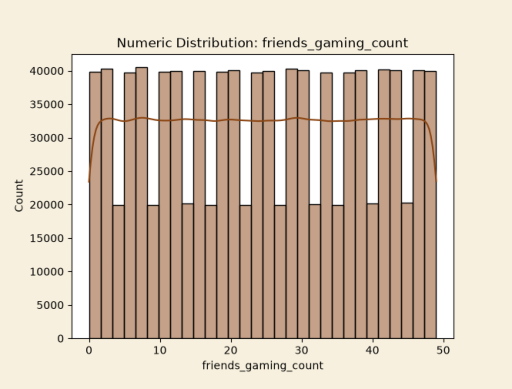

./png_full\online_friendsdist.png already exists; importing...


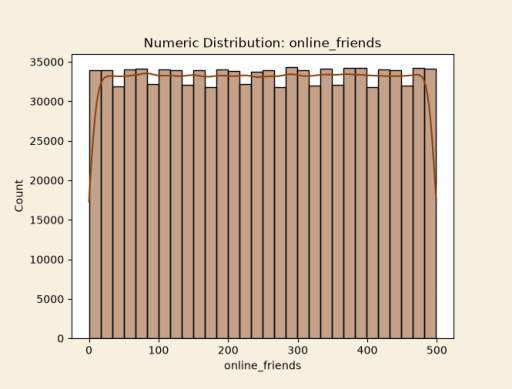

./png_full\streaming_hoursdist.png already exists; importing...


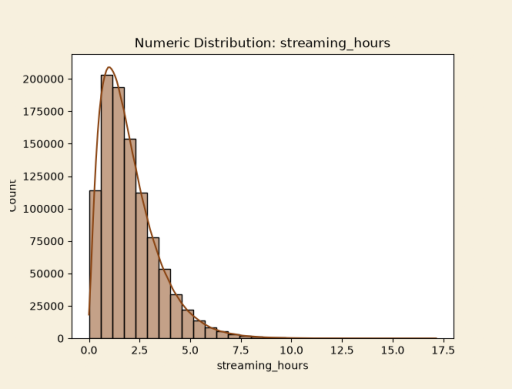

./png_full\esports_interestdist.png already exists; importing...


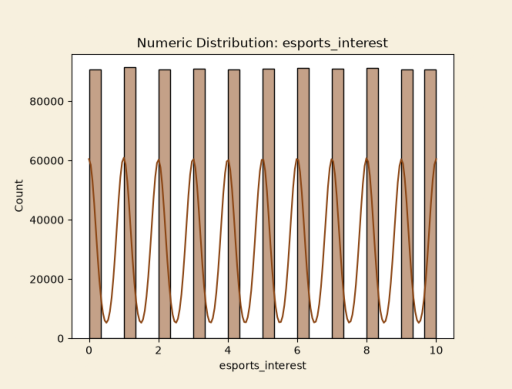

./png_full\headset_usagedist.png already exists; importing...


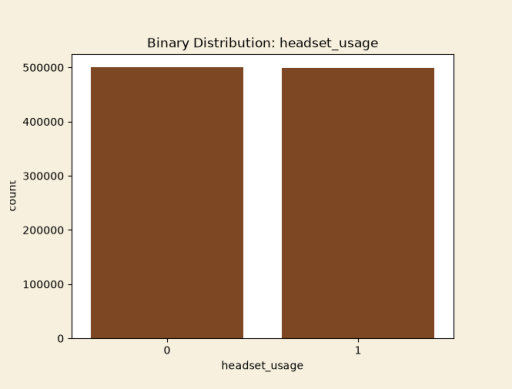

./png_full\microtransactions_spendingdist.png already exists; importing...


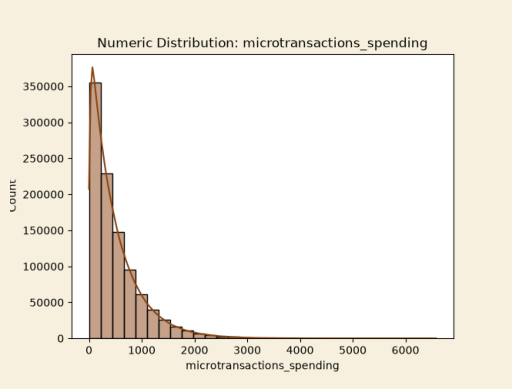

./png_full\parental_supervisiondist.png already exists; importing...


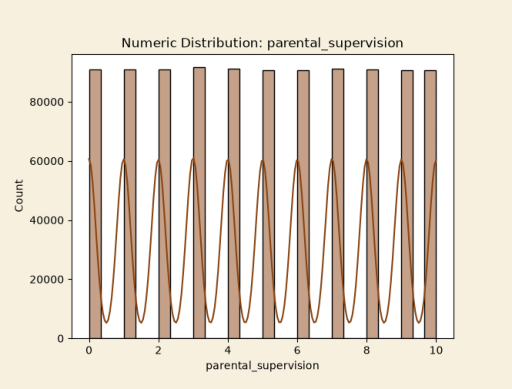

./png_full\loneliness_scoredist.png already exists; importing...


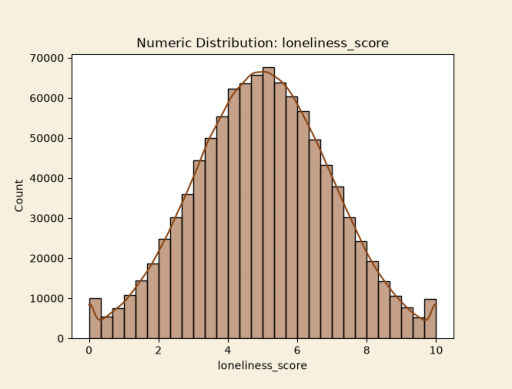

./png_full\aggression_scoredist.png already exists; importing...


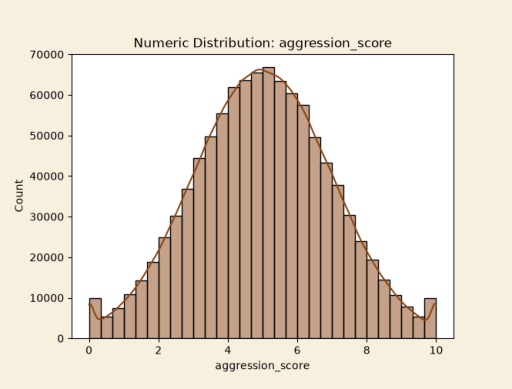

./png_full\happiness_scoredist.png already exists; importing...


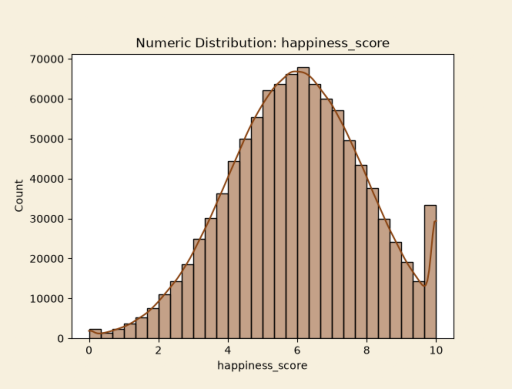

./png_full\bmidist.png already exists; importing...


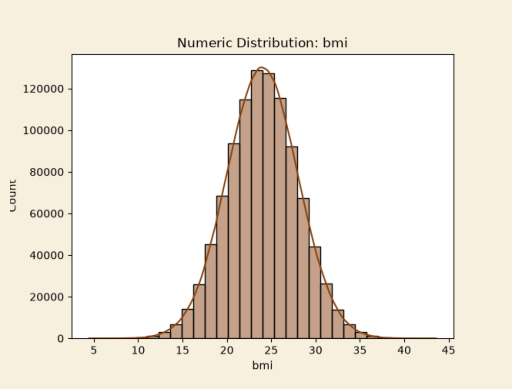

./png_full\screen_time_totaldist.png already exists; importing...


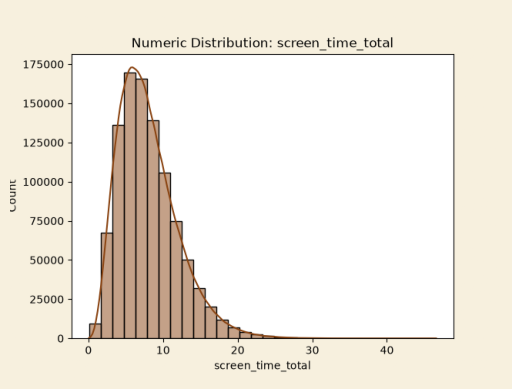

./png_full\eye_strain_scoredist.png already exists; importing...


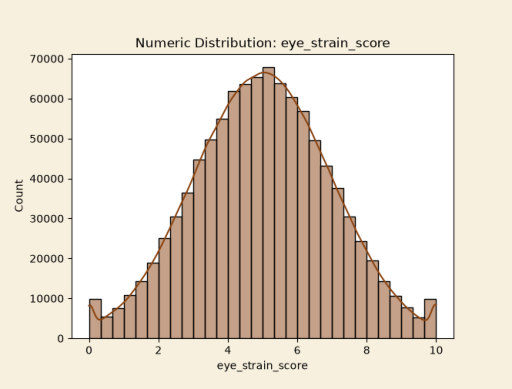

./png_full\back_pain_scoredist.png already exists; importing...


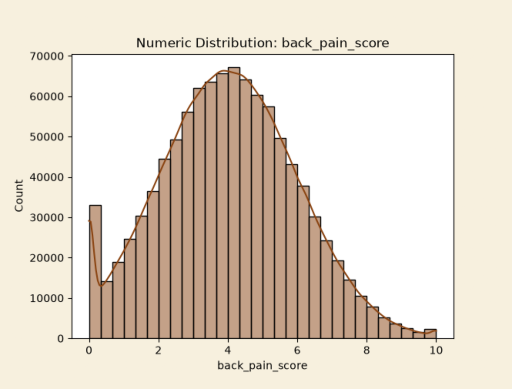

./png_full\competitive_rankdist.png already exists; importing...


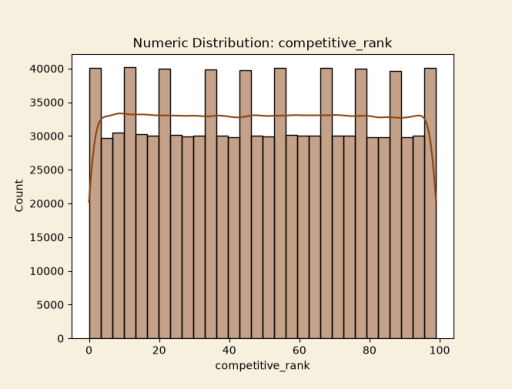

./png_full\internet_qualitydist.png already exists; importing...


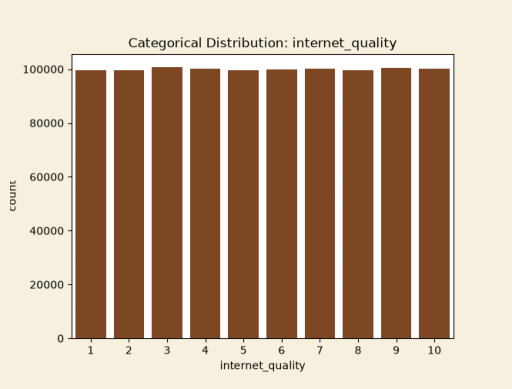

In [35]:
# Check for / create output folders
output_folder_full = './png_full'
output_folder_subset = './png_subset'
os.makedirs(output_folder_full, exist_ok=True)
os.makedirs(output_folder_subset, exist_ok=True)

# Create distribution plots for full dataset
for col in inf_data.columns:
    unique_vals = inf_data[col].nunique()
    dtype = inf_data[col].dtype
    filename = os.path.join(output_folder_full, f'{col}dist.png')

    if not os.path.exists(filename):
        plt.figure()
        if unique_vals == 2:
            sns.countplot(x=col, data=inf_data, color='saddlebrown')
            plt.title(f'Binary Distribution: {col}')
        elif dtype == 'object' or unique_vals <= 10:
            sns.countplot(x=col, data=inf_data, color='saddlebrown')
            plt.title(f'Categorical Distribution: {col}')
        else:
            sns.histplot(inf_data[col], bins=30, kde=True, color='saddlebrown')
            plt.title(f'Numeric Distribution: {col}')
        plt.savefig(filename)
        plt.show()
        plt.close()
    else:
        print(f'{filename} already exists; importing...')
        img = Image.open(filename)
        plt.imshow(img)
        plt.axis('off')
        plt.show()


./png_subset\subsetagedist.png already exists; importing...


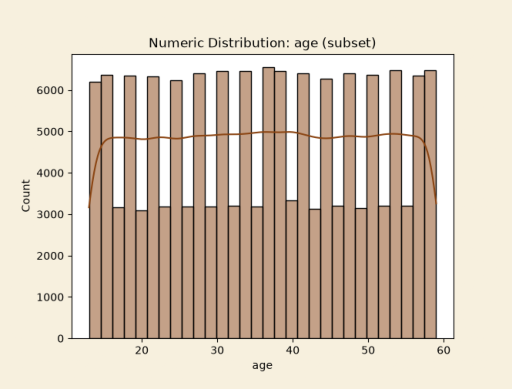

./png_subset\subsetgenderdist.png already exists; importing...


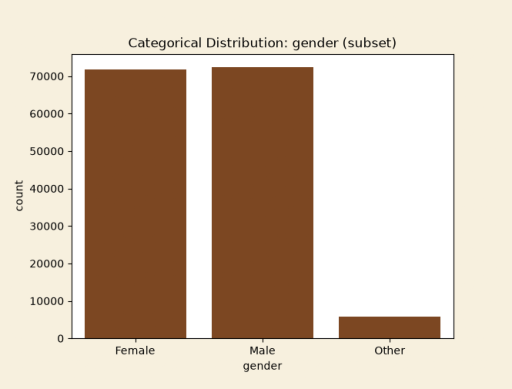

./png_subset\subsetincomedist.png already exists; importing...


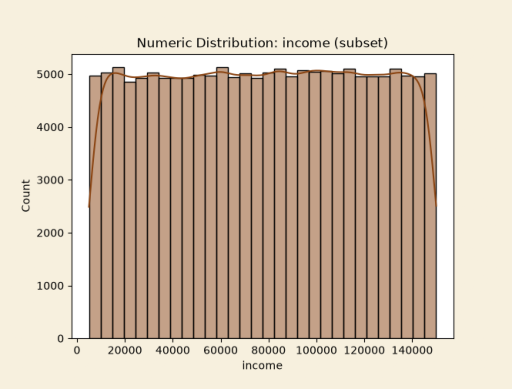

./png_subset\subsetdaily_gaming_hoursdist.png already exists; importing...


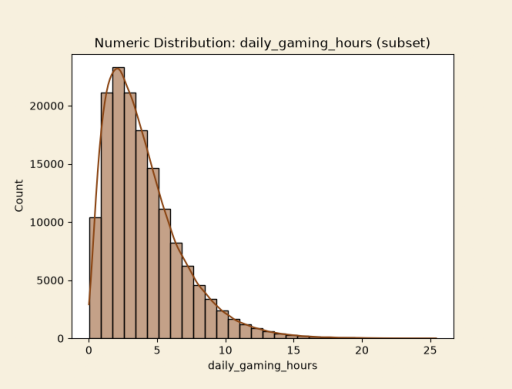

./png_subset\subsetweekly_sessionsdist.png already exists; importing...


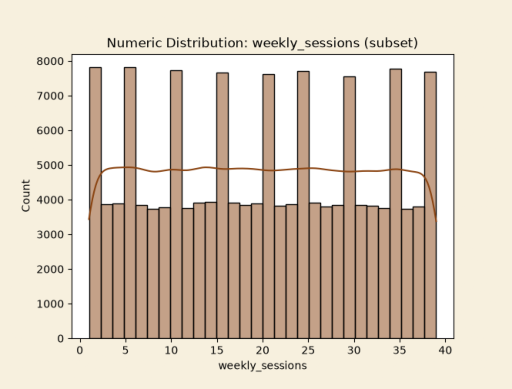

./png_subset\subsetyears_gamingdist.png already exists; importing...


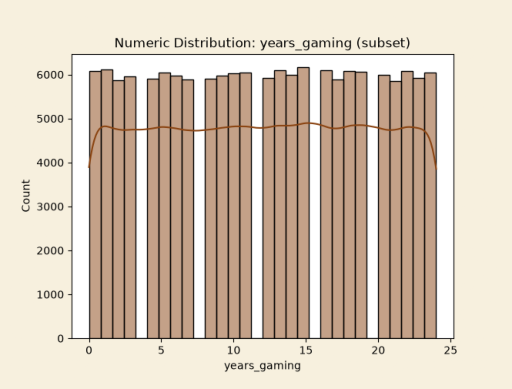

./png_subset\subsetsleep_hoursdist.png already exists; importing...


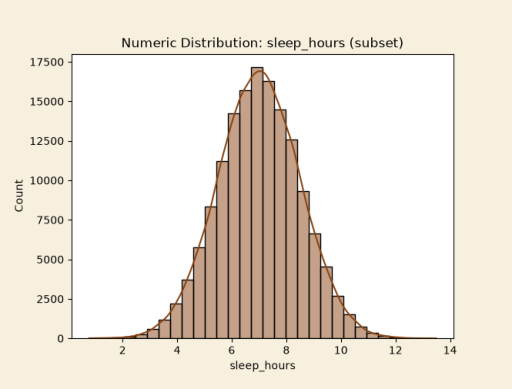

./png_subset\subsetcaffeine_intakedist.png already exists; importing...


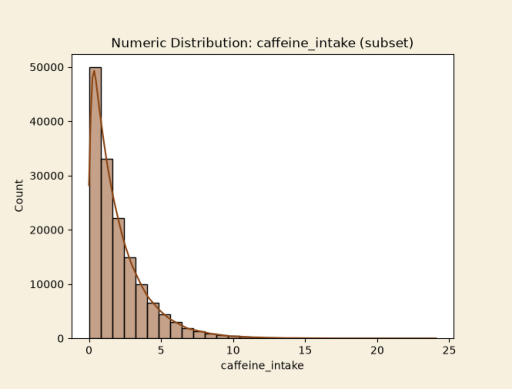

./png_subset\subsetexercise_hoursdist.png already exists; importing...


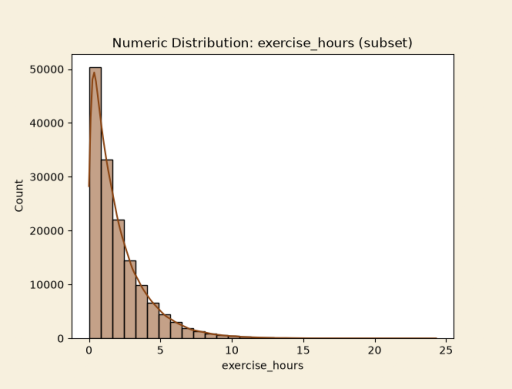

./png_subset\subsetstress_leveldist.png already exists; importing...


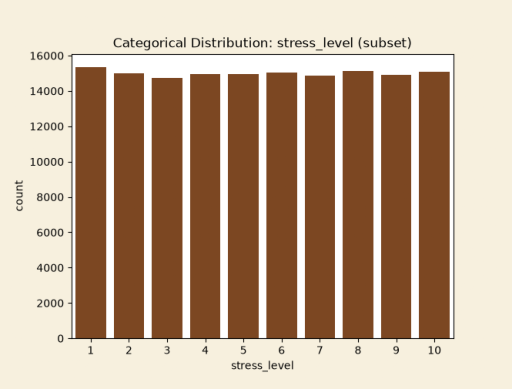

./png_subset\subsetanxiety_scoredist.png already exists; importing...


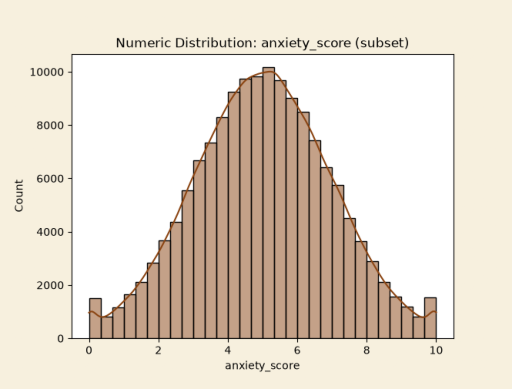

./png_subset\subsetdepression_scoredist.png already exists; importing...


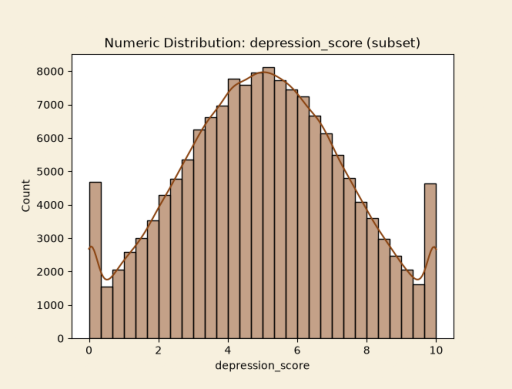

./png_subset\subsetsocial_interaction_scoredist.png already exists; importing...


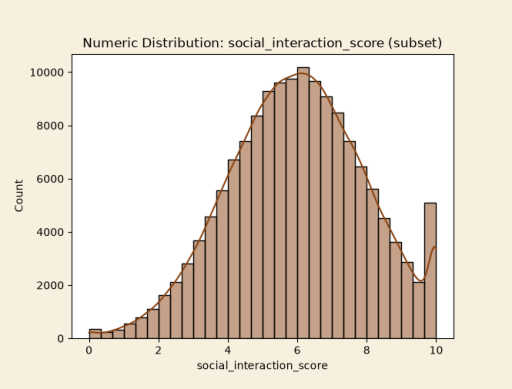

./png_subset\subsetrelationship_satisfactiondist.png already exists; importing...


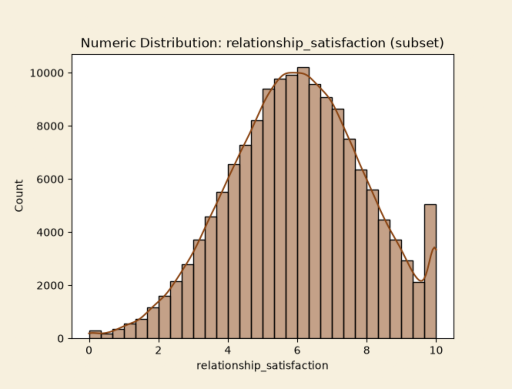

./png_subset\subsetacademic_performancedist.png already exists; importing...


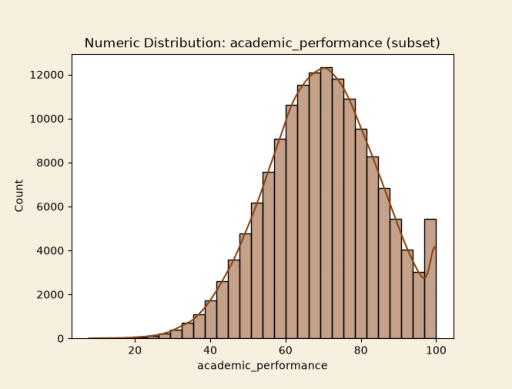

./png_subset\subsetwork_productivitydist.png already exists; importing...


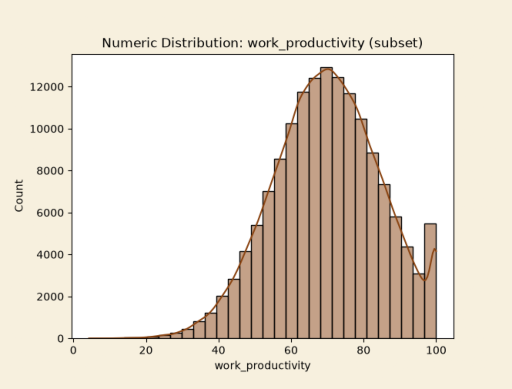

./png_subset\subsetaddiction_leveldist.png already exists; importing...


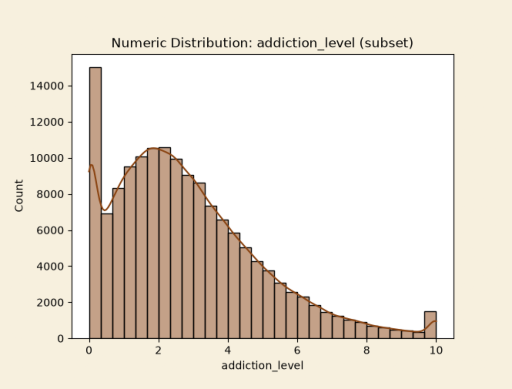

./png_subset\subsetmultiplayer_ratiodist.png already exists; importing...


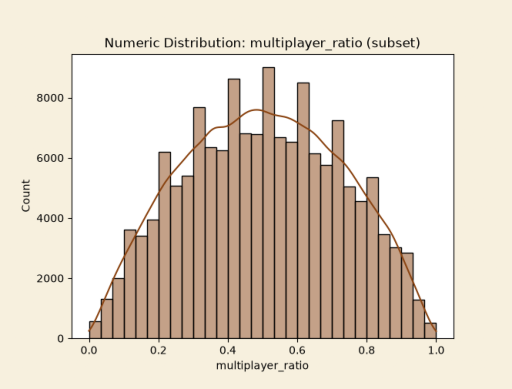

./png_subset\subsettoxic_exposuredist.png already exists; importing...


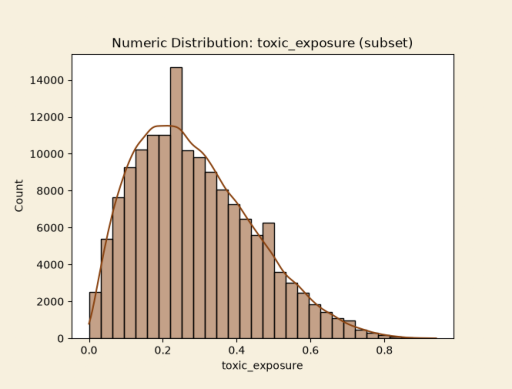

./png_subset\subsetviolent_games_ratiodist.png already exists; importing...


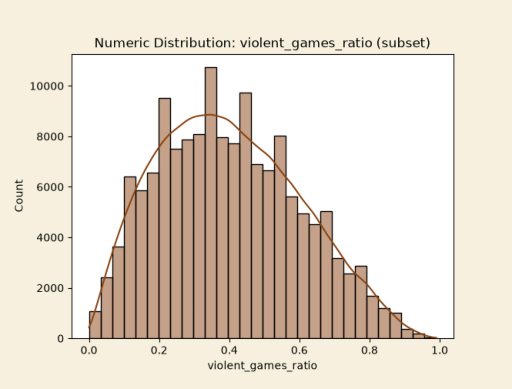

./png_subset\subsetmobile_gaming_ratiodist.png already exists; importing...


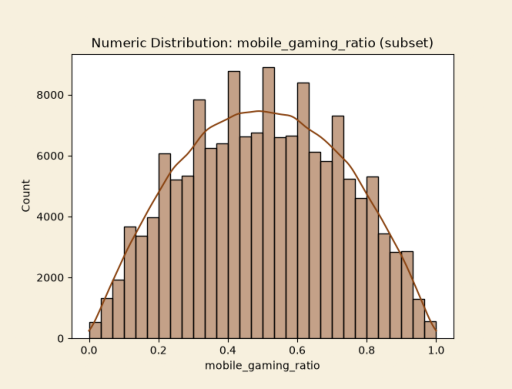

./png_subset\subsetnight_gaming_ratiodist.png already exists; importing...


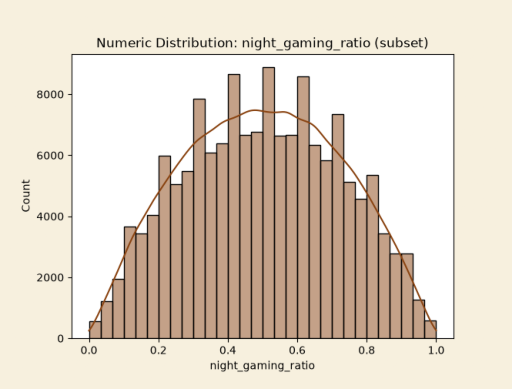

./png_subset\subsetweekend_gaming_hoursdist.png already exists; importing...


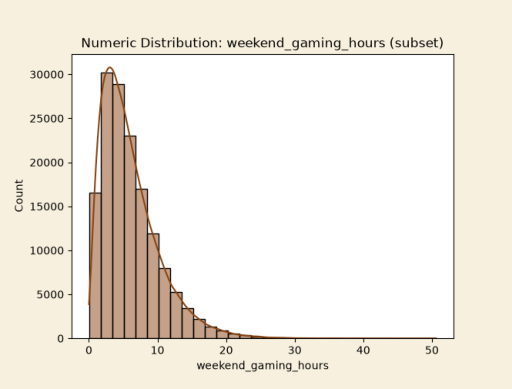

./png_subset\subsetfriends_gaming_countdist.png already exists; importing...


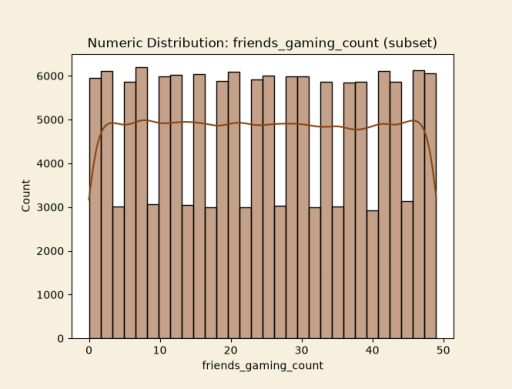

./png_subset\subsetonline_friendsdist.png already exists; importing...


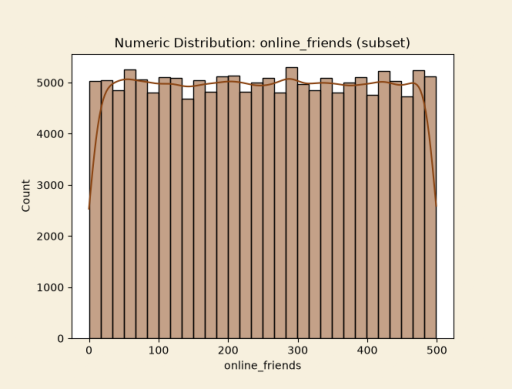

./png_subset\subsetstreaming_hoursdist.png already exists; importing...


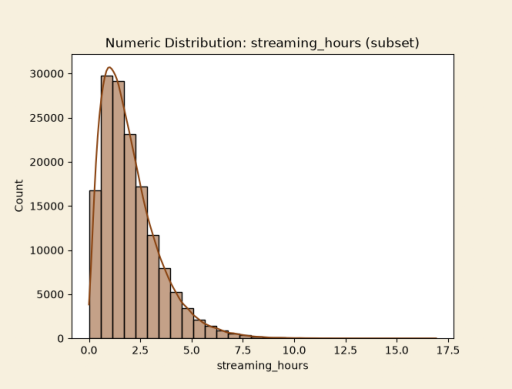

./png_subset\subsetesports_interestdist.png already exists; importing...


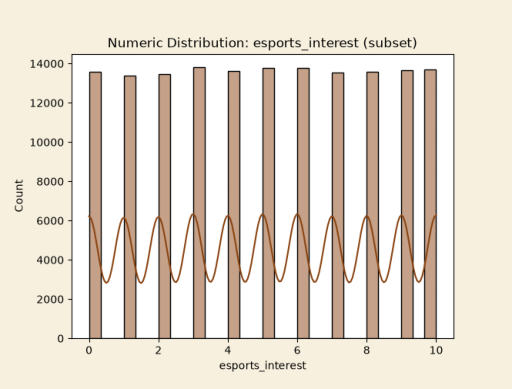

./png_subset\subsetheadset_usagedist.png already exists; importing...


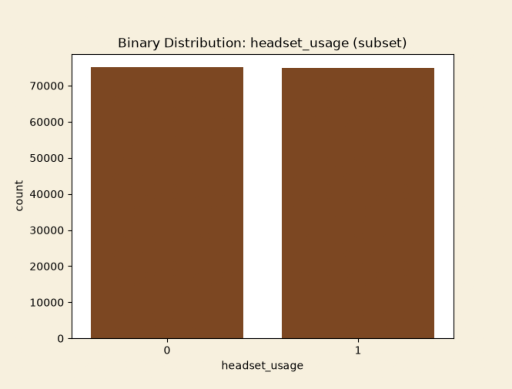

./png_subset\subsetmicrotransactions_spendingdist.png already exists; importing...


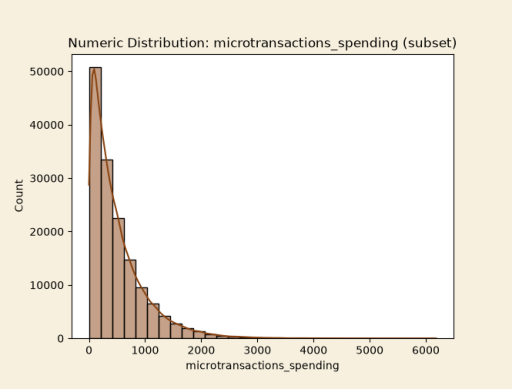

./png_subset\subsetparental_supervisiondist.png already exists; importing...


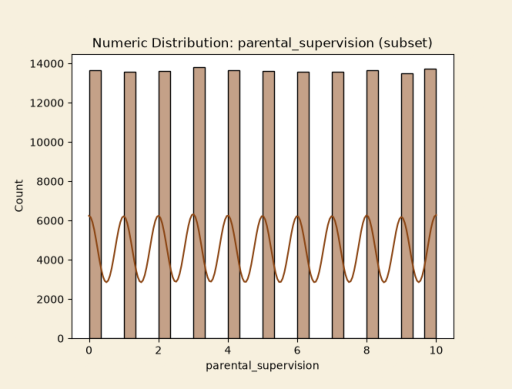

./png_subset\subsetloneliness_scoredist.png already exists; importing...


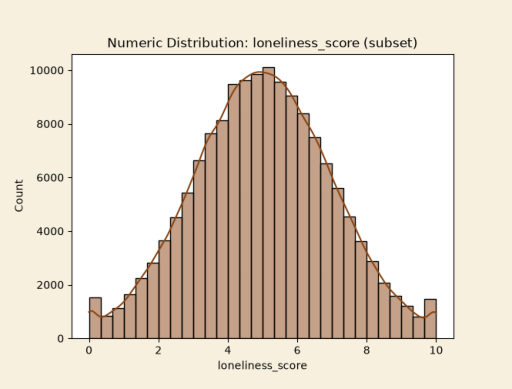

./png_subset\subsetaggression_scoredist.png already exists; importing...


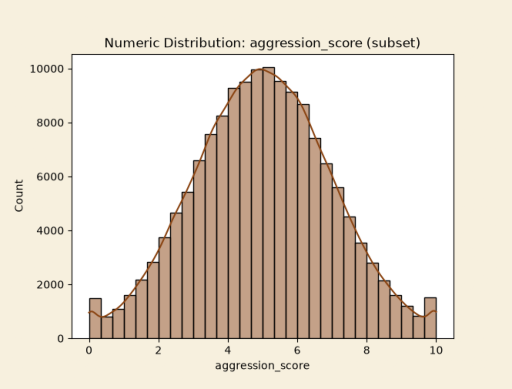

./png_subset\subsethappiness_scoredist.png already exists; importing...


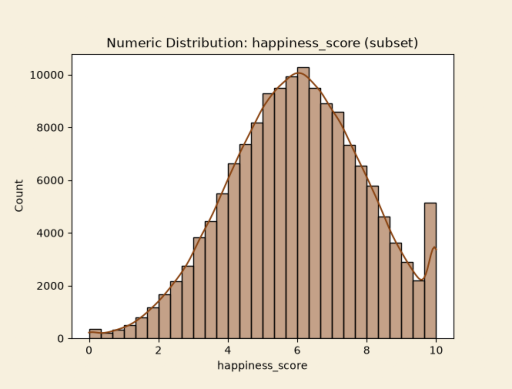

./png_subset\subsetbmidist.png already exists; importing...


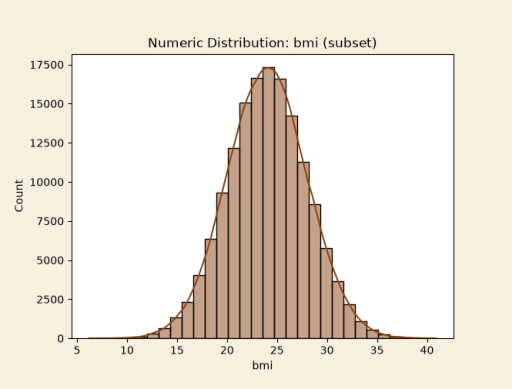

./png_subset\subsetscreen_time_totaldist.png already exists; importing...


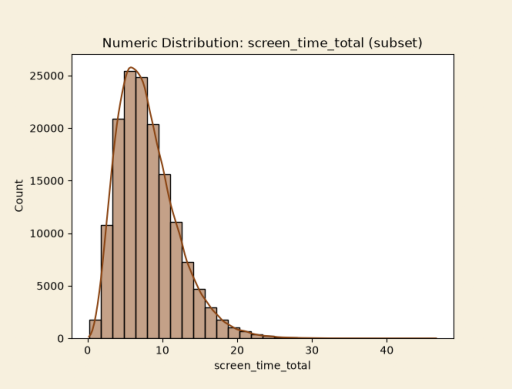

./png_subset\subseteye_strain_scoredist.png already exists; importing...


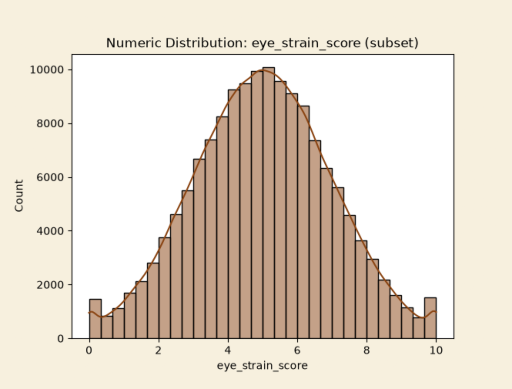

./png_subset\subsetback_pain_scoredist.png already exists; importing...


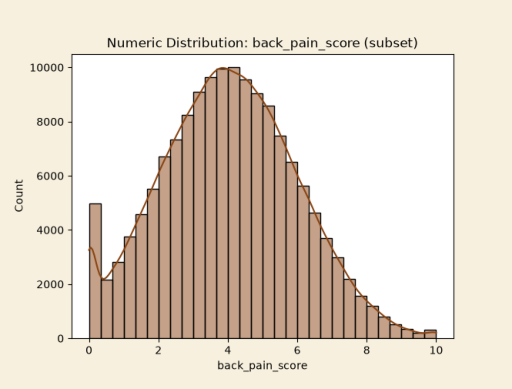

./png_subset\subsetcompetitive_rankdist.png already exists; importing...


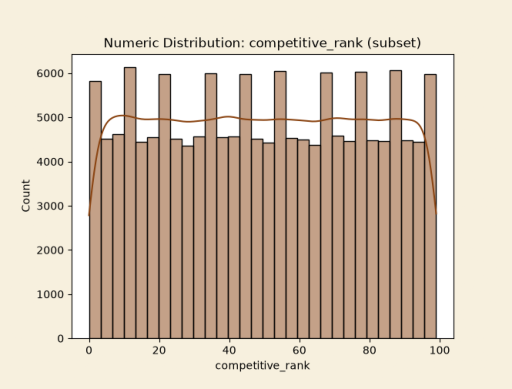

./png_subset\subsetinternet_qualitydist.png already exists; importing...


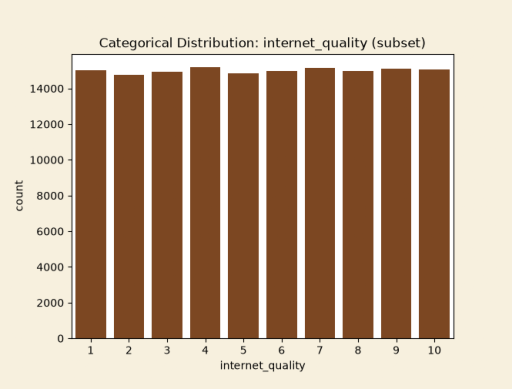

In [36]:
# Create distribution plots for data subset
for col in df.columns:
    unique_vals = df[col].nunique()
    dtype = df[col].dtype
    filename = os.path.join(output_folder_subset, f'subset{col}dist.png')

    if not os.path.exists(filename):
        plt.figure()
        if unique_vals == 2:
            sns.countplot(x=col, data=df, color='saddlebrown')
            plt.title(f'Binary Distribution: {col} (subset)')
        elif dtype == 'object' or unique_vals <= 10:
            sns.countplot(x=col, data=df, color='saddlebrown')
            plt.title(f'Categorical Distribution: {col} (subset)')
        else:
            sns.histplot(df[col], bins=30, kde=True, color='saddlebrown')
            plt.title(f'Numeric Distribution: {col} (subset)')
        plt.savefig(filename)
        plt.show()
        plt.close()
    else:
        print(f'{filename} already exists; importing...')
        img = Image.open(filename)
        plt.imshow(img)
        plt.axis('off')
        plt.show()

Our visualisations suggest that the sampled data is representative of the full dataset, and reasonably balanced. 
Following on from this step, we can explore the features of the dataset using the graphs.

The individual distribution graphs are a lot to unpack at first glance, but here are some initial observations we can make:
- A number of the columns, such as `eye_strain_score` and `esports_interest` are scores between 1-10, while others such as `night_gaming_ratio` are ratios between 0-1.
- Some columns such as `interney_quality` appear to have very little variation in the distributions of values; a possible explanation may be the sheer volume of data causing smaller patterns in the data to be harder to pick up on. This may also be due to the synthetic nature of the data lacking the irregularities which real-world data might have.
- Most of the distributions are fairly balanced, and do not appear to have any outliers.
- The distributions of the subset data are well-balanced and sufficiently representative of the full data.

**Checking assumptions of causal inference:**

- **SUTVA (Stable Unit Treatment Value Assumption):** We assume that each individual's outcome depends only on their own treatment status and that the treatment is applied consistently across all individuals.
- **Exchangeability/Ignorability:** We have listed potential confounders that may affect both the **treatment** (X) and the **outcome** (Y). We will extract these variables from our data and adjust for them in the analysis to help satisfy the ignorability assumption.
- **No Multicollinearity:** We will use a **heatmap** and **pair plot** to examine correlations among the confounders. High correlations may indicate multicollinearity, which can affect the stability and interpretability of our model.
- **Overlap (Positivity):** By plotting the confounders against the treatment (`gaming_hrs`) and outcome (`m_health`) variables, we will check that there is **sufficient overlap in the distribution of confounders** across treatment groups. This ensures that there are both 'treated' and 'untreated' individuals for each value of the confounders.

.png\pairplot.png already exists; importing...


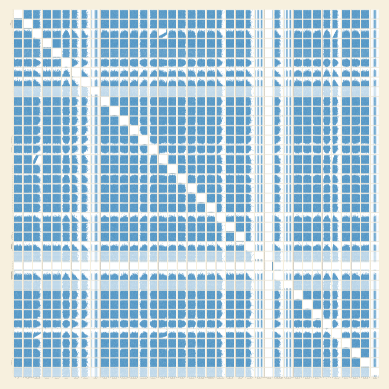

In [37]:
# Plot pairplot (Ignorability)

output_folder_full = '.png'
os.makedirs(output_folder_full, exist_ok=True)

filename = os.path.join(output_folder_full, 'pairplot.png')

if not os.path.exists(filename):
    pairplot = sns.pairplot(df)
    plt.savefig(filename)
    plt.show()
    plt.close()
else:
    print(f'{filename} already exists; importing...')
    img = Image.open(filename)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


The pairplot created is very large due to the **high number of columns** in our dataset (39 columns). This limits our ability to visually assess multicollinearity among confounders. Instead, we will use a heatmap to plot the correlations between variables. While this will summarise the patterns in the data, we **may miss some detailed relationships**. 

.png\heatmapcorr.png already exists; importing...


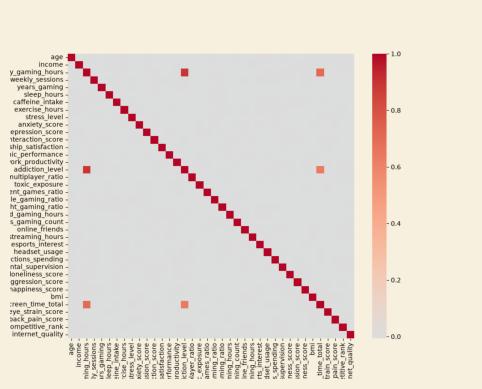

In [38]:
# Drop non-numeric columns
num_df = df.select_dtypes(include='number')
corr_matrix = num_df.corr()

# Plot heatmap
output_folder_full = '.png'
os.makedirs(output_folder_full, exist_ok=True)

filename = os.path.join(output_folder_full, 'heatmapcorr.png')

if not os.path.exists(filename):
    plt.figure(figsize=(10,8))
    sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
    plt.savefig(filename)
    plt.show()
    plt.close()
else:
    print(f'{filename} already exists; importing...')
    img = Image.open(filename)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


The heatmap shows three notable correlations. The strongest is between '`addiction_level`' and '`daily_gaming_hours`' (about 0.8). The correlations between '`addiction_level`' and '`screen_time_total`', and between '`screen_time_total`' and '`daily_gaming_hours`', are moderate (about 0.6–0.4). 

To explore these relationships further, we will subset the `df` dataframe and create a `pairplot` with fewer columns. This will help us focus on the variables with interesting patterns and better assess multicollinearity among our confounders.

Index(['income', 'sleep_hours', 'caffeine_intake', 'addiction_level',
       'streaming_hours', 'microtransactions_spending', 'loneliness_score',
       'screen_time_total', 'eye_strain_score'],
      dtype='str')
.png\pairplot2.png already exists; importing...


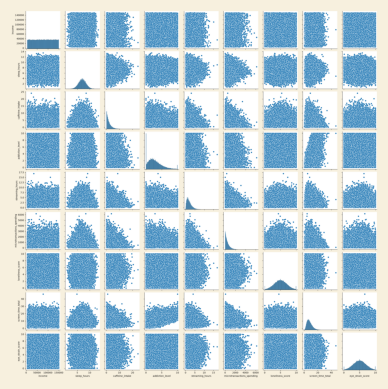

In [39]:
# Subset required columns
subset = [
    'income', 'sleep_hours', 'caffeine_intake', 
    'addiction_level', 'streaming_hours', 
    'microtransactions_spending', 'loneliness_score', 
    'screen_time_total', 'eye_strain_score'
]
subset_df = df[subset]
print(subset_df.columns)

# Plot
output_folder_full = '.png'
os.makedirs(output_folder_full, exist_ok=True)

filename = os.path.join(output_folder_full, 'pairplot2.png')

if not os.path.exists(filename):
    pairplot = sns.pairplot(subset_df)
    pairplot.savefig(filename)
    plt.show()
    plt.close()
else:
    print(f'{filename} already exists; importing...')
    img = Image.open(filename)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

The new pair plot is much easier to interpret. We can take note of the following:
- `screen_time_total` and `addiction_level` show a linear correlation, indicating multicollinearity. This may make it harder to separate their effects in the model.
- Some variables display distinct outliers, which is common in real-world data. We may consider removing these if they strongly affect distributions.
- `sleep_hours` forms a centralised cluster when compared to other variables.

There are some other noticeable patterns that would be interesting to explore further with EDA, but for now, the aforementioned observations suffice for the focus of this beginner project.

Presently, our data will be difficult to check for **overlap** since the treatment and outcome variables have not yet been established as `X` and `Y`. We will perform data cleaning and preprocess the variables we require for measuring our causal estimand, the 'Average Treatment Effect' (ATE).

We will then move to the **`R` notebook** where we will check for overlap by plotting a histogram or density plot of propensity scores for each group (treated vs. untreated).

In [40]:
# Remove unrelated columns
subset = [
        'age', 'income', 'daily_gaming_hours', 'weekly_sessions',
       'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
       'stress_level', 'anxiety_score', 'depression_score',
       'social_interaction_score', 'relationship_satisfaction',
       'academic_performance', 'work_productivity', 'addiction_level',
       'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
       'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
       'friends_gaming_count', 'online_friends', 'streaming_hours',
       'esports_interest', 'microtransactions_spending',
       'parental_supervision', 'loneliness_score', 'aggression_score',
       'happiness_score', 'bmi', 'screen_time_total', 'eye_strain_score',
       'back_pain_score', 'competitive_rank'
]
caus_df = df[subset]

The new subset of data excludes any columns that involve bias (such as `gender`) or are simply not relevant to the current focus, such as `internet_quality`.

Creating the X and Y variables poses a challenge because the data required for the treatment and outcome variables are spread across multiple columns in our `caus_df` dataframe. There are a couple of ways to tackle this, of which we have chosen the most straightforward:
- **Treatment (X)**: 
    - We will combine columns that represent time spent gaming, in this case, `daily_gaming_hours` and `weekly_sessions`, to create a single variable (`gaming_hrs`) that represents the total weekly gaming hours. To do this, we will be multiplying `daily_gaming_hours` by `weekly_sessions` for a weekly estimate. 
    - Adding `weekend_gaming_hours` to the weekly estimate would be key if these hours are not already included in `weekly_sessions`, but as we have no way of telling, we will leave this out **as a recognised limitation** of this project.
- **Outcome (Y)**:
    - We will **standardise** and then **aggregate** scores from the `stress_level`, `anxiety_score`, `depression_score`, `loneliness_score` and `aggression_score` columns to calculate an average mental health score (`m_health`) for each individual. 
    - As `happiness_score` is a positive mental health score, it will be **subtracted from rather than added to** the overall `m_health` score. So that higher values to mean better mental health, we will multiply the whole expression by -1.


In [41]:
# Create X and Y variables
# X - gaming_hrs
caus_df['gaming_hrs'] = caus_df.daily_gaming_hours * caus_df.weekly_sessions
print(caus_df.head())

# Y - m_health
column_list = caus_df[[
    'stress_level', 
    'anxiety_score', 
    'depression_score', 
    'loneliness_score', 
    'aggression_score', 
    'happiness_score'
    ]]

caus_df[['z_stress', 'z_anxiety', 'z_depression', 'z_loneliness', 'z_aggression', 'z_happiness']] = (column_list-column_list.mean())/column_list.std()
caus_df['m_health'] = ((caus_df.z_stress + caus_df.z_anxiety + caus_df.z_depression + caus_df.z_loneliness + caus_df.z_aggression - caus_df.z_happiness) / 6)  * -1
print(caus_df.head())


        age  income  daily_gaming_hours  weekly_sessions  years_gaming  \
266400   54   85406                1.08               20            24   
306111   39   52223                3.54               16            11   
277014   25  115189                4.94               10             0   
783385   49   74798                1.75               25             6   
60375    55   41451                1.43               11             0   

        sleep_hours  caffeine_intake  exercise_hours  stress_level  \
266400         7.72             5.60            1.91             4   
306111         7.09             0.79            0.29             7   
277014         7.24             1.67            0.05             4   
783385         8.26             0.42            0.37             9   
60375          8.00             0.17            2.41             9   

        anxiety_score  ...  parental_supervision  loneliness_score  \
266400           3.66  ...                    10              3.

Our data is now preprocessed and ready to check for the **causal assumption of overlap**.
This concludes the EDA and preprocessing stages of our causal analysis. 

We will proceed with the remaining stages of this project in the R notebook linked here: [caus_inf_spec2.Rmd]('https://github.com/FaatimahMajothi98/Causal-Inference-Analysis/blob/master/caus_inf_spec2.Rmd')

In [42]:
# Export data
if os.path.exists('caus_df.csv'):
    print('.csv exists, done.')
else:
    caus_df.to_csv('caus_df.csv', index=False)
    print('CSV exported'
    '.')

CSV exported.
